In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv


# Heavy Equipment Selling Price Prediction Challenge

## 1. Project Overview
This project is a Machine Learning Regression task where the goal is to predict the auction selling price (`TargetValue`) of used heavy equipment (such as excavators, bulldozers, and tractors) based on their usage, machine specifications, configuration, and sale timing.

## 2. Problem Statement
Accurately pricing heavy machinery in the secondary market is challenging due to varying usage hours, age, brand features, and high missing data rates. By building an end-to-end Machine Learning pipeline, we aim to minimize prediction error, evaluated using **Root Mean Squared Log Error (RMSLE)**.

## 3. Project Workflow
1. **Data Loading & Exploratory Data Analysis (EDA):** Inspecting shapes, distributions, target skewness, and missing values.
2. **Feature Engineering:** Creating domain-specific features like machine age, usage rates, and high-cardinality frequency encoding.
3. **Preprocessing Pipeline:** Imputation, categorical ordinal encoding, and data leakage prevention using `ColumnTransformer` and `Pipeline`.
4. **Model Training & Evaluation:** Comparing Ridge, Random Forest, XGBoost, and LightGBM base models.


## 2. Importing Libraries
Importing necessary Python libraries for data manipulation, visualization, preprocessing, pipeline building, machine learning models, text feature extraction, and model evaluation metrics.

In [2]:
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold, cross_val_score

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OrdinalEncoder

from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

from sklearn.metrics import mean_squared_log_error

## 2. Data Loading & Initial Inspection

In this step, we load the dataset files provided in the competition:
* **`train.csv`**: Primary training set containing asset attributes, configuration specs, usage metrics, and the target variable (`TargetValue`).
* **`test.csv`**: Unseen test set used for final predictions and evaluation on the leaderboards.
* **`metadata.csv`**: Supplementary feature descriptors and system metadata.

We inspect the dimensions (rows and columns) of each DataFrame to verify successful loading.

In [3]:
train = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv')
metadata = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv')

print("Train Shape:", train.shape)
print("Test Shape:", test.shape)
print("Metadata Shape:", metadata.shape)

Train Shape: (138701, 50)
Test Shape: (15000, 49)
Metadata Shape: (50, 2)


## Initial Exploratory Data Analysis: Data Schema & Target Statistics

Examining the top rows, column schemas, data types, and summary statistics of the target variable (`TargetValue`) to understand the dataset's underlying structure.

In [4]:
display(train.head())

print("\nColumns:")
print(train.columns.tolist())

print("\nData Types:")
display(train.dtypes)

print("\nTarget Statistics:")
display(train['TargetValue'].describe())

,TransactionID,TargetValue,AssetID,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,TransactionDate,...,col20,col21,col22,col23,col24,col25,col27,col28,col29,col30
0,1139309,57000.0,117665,88,ACH138,GTX,1997,4640.0,Low,2005-03-26,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional
1,1139316,26500.0,1001282,4616,ACH138,GTX,2005,508.0,Low,2009-12-18,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1139317,21000.0,772709,1948,ACH138,GTX,1994,11540.0,High,2005-08-26,...,Steel,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN
3,1139322,27000.0,902010,3550,ACH138,GTX,2002,4883.0,High,2006-11-17,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1139333,21500.0,1036259,36014,ACH138,GTX,2009,302.0,Low,2010-08-27,...,Rubber,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN



Columns:
['TransactionID', 'TargetValue', 'AssetID', 'ProductConfigID', 'DataOriginCode', 'VendorPartnerID', 'ManufactureYear', 'OperationalHoursMeter', 'UtilizationTier', 'TransactionDate', 'Spec_FullDescriptor', 'Spec_BaseClass', 'Spec_SubClass', 'Spec_ReleaseSeries', 'Spec_VariantModifier', 'AssetScaleFactor', 'FunctionalClassification', 'RegionCode', 'InventoryGroupCategory', 'InventoryGroupDescription', 'col1', 'CabinType', 'Forks', 'col3', 'col4', 'DrivetrainType', 'col5', 'col6', 'col7', 'col8', 'col9', 'col10', 'col11', 'col12', 'col13', 'col14', 'col15', 'col16', 'col18', 'col19', 'col20', 'col21', 'col22', 'col23', 'col24', 'col25', 'col27', 'col28', 'col29', 'col30']

Data Types:


TransactionID                  int64
TargetValue                  float64
AssetID                        int64
ProductConfigID                int64
DataOriginCode                object
VendorPartnerID               object
ManufactureYear                int64
OperationalHoursMeter        float64
UtilizationTier               object
TransactionDate               object
Spec_FullDescriptor           object
Spec_BaseClass                object
Spec_SubClass                 object
Spec_ReleaseSeries            object
Spec_VariantModifier          object
AssetScaleFactor              object
FunctionalClassification      object
RegionCode                    object
InventoryGroupCategory        object
InventoryGroupDescription     object
col1                          object
CabinType                     object
Forks                         object
col3                          object
col4                          object
DrivetrainType                object
col5                          object
c


Target Statistics:


count    138701.000000
mean      41521.874047
std       26361.125948
min        7500.000000
25%       20500.000000
50%       35000.000000
75%       57000.000000
max      142000.000000
Name: TargetValue, dtype: float64

**FINDING MISSING VALUES**

In [5]:
missing = train.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print("Columns with Missing Values:", len(missing))

display(missing.head(20))

Columns with Missing Values: 35


col18                 138635
col19                 138635
col4                  128320
col5                  128320
col28                 123742
col27                 123742
col30                 119829
col29                 119829
col14                 115296
col11                 115296
col13                 115296
col8                  115296
col9                  115296
col6                  115296
col7                  115296
col3                  109448
Forks                 109382
Spec_ReleaseSeries    105805
col1                  104915
col12                 100337
dtype: int64

## 3. Exploratory Data Analysis (EDA)

### Target Distribution 

Analyzing the distribution of the target variable (`TargetValue`). Real-world financial transaction data often exhibits high right-skewness due to extreme high-value assets.

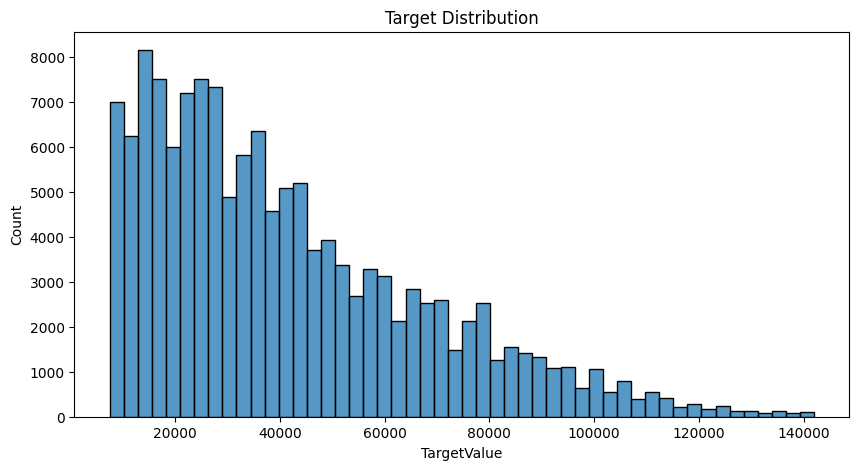

In [6]:
plt.figure(figsize=(10,5))
sns.histplot(train['TargetValue'], bins=50)
plt.title("Target Distribution")
plt.show()

**Log Target Distribution**

> **Observation & Insight:**
> * **Extreme Right Skewness:** The distribution plot confirms that `TargetValue` is heavily skewed to the right. Most heavy machinery selling prices lie in the lower-to-mid range, with a few very expensive assets stretching the tail.
> * **Action Taken:** To reduce variance, stabilize the gradients, and align with the **RMSLE** evaluation metric, we apply a Log Transformation ($\log(1+x)$) on the target variable before model training.

### Log-Transformed Target Distribution (`np.log1p`)

Applying log transformation (`np.log1p`) to the target variable (`TargetValue`) to eliminate extreme right-skewness and stabilize target variance for regression algorithms.

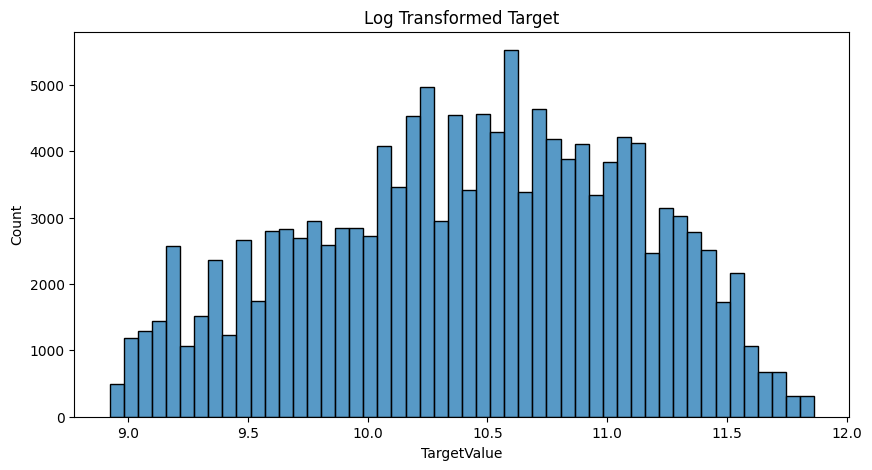

In [7]:
plt.figure(figsize=(10,5))
sns.histplot(np.log1p(train['TargetValue']), bins=50)
plt.title("Log Transformed Target")
plt.show()

> **EDA Insight & Key Takeaway:**
> * **Normal Bell Curve Shape:** Applying `np.log1p`(to convert into small scale) transforms the original heavily skewed distribution into an approximately normal (Gaussian) bell curve.
> * **Inference Step:** During final model evaluation/predictions, we apply the inverse function `np.expm1` to restore predictions back to the original Rupee/Dollar price scale.

### Feature Classification: Numerical & Categorical Column Identification

Separating dataset features into numerical and categorical subsets to apply target-specific preprocessing strategies (imputation and encoding). Identifiers (`TransactionID`) and the target variable (`TargetValue`) are excluded from feature sets.

In [8]:
numerical_cols = train.select_dtypes(include=['int64','float64']).columns.tolist()

categorical_cols = train.select_dtypes(include=['object']).columns.tolist()

numerical_cols.remove('TargetValue')
numerical_cols.remove('TransactionID')

print("Numerical Columns:", len(numerical_cols))
print("Categorical Columns:", len(categorical_cols))

Numerical Columns: 4
Categorical Columns: 44


> **Feature Division Summary:**
> * **Numerical Columns:** Continuous and discrete numeric measurements (e.g., machine age, operational hours meter, regional codes).
> * **Categorical Columns:** Text descriptors, configuration IDs, and category tiers requiring ordinal encoding before training tree models.
> * **Exclusions:** `TransactionID` (not needed for pricing) and `TargetValue` (target variable) are removed to prevent data leakage.

### Missing Values Visualization

Plotting a bar chart for the top 20 columns with the highest missing value counts. This helps us visualize feature sparsity and verify why robust imputation strategies are required before training machine learning models.

**Missing Value Visualization**

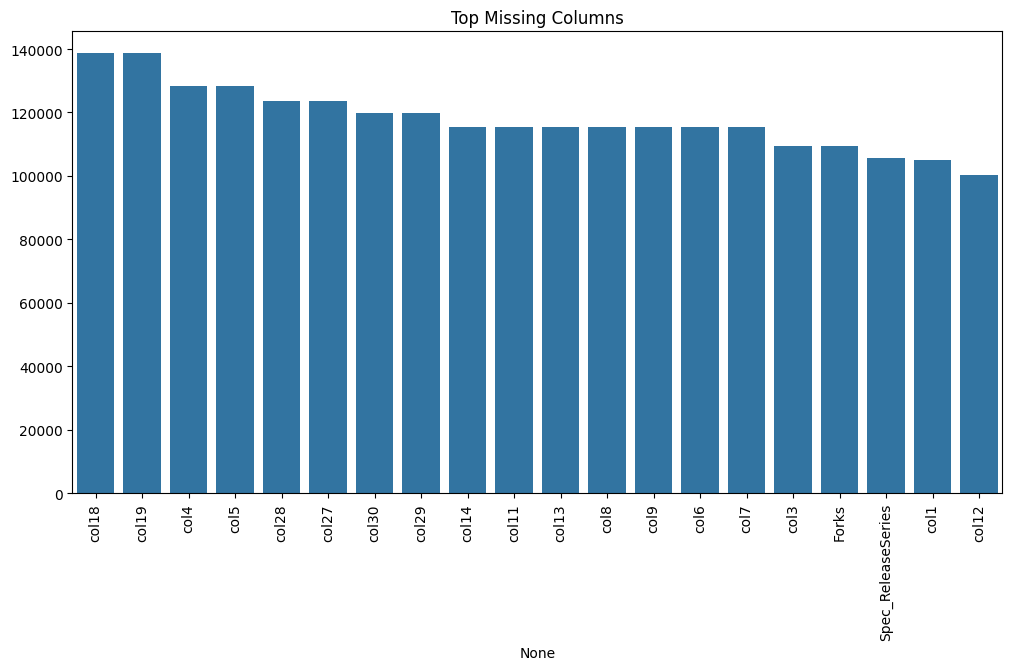

In [9]:
plt.figure(figsize=(12,6))

sns.barplot(
    x=missing.index[:20],
    y=missing.values[:20]
)

plt.xticks(rotation=90)
plt.title("Top Missing Columns")
plt.show()

> **EDA Insight:**
> * **High Sparsity in Optional Equipment:** Many optional machinery features (like attachments, specs, and specific modifiers) contain a large number of `NaN` values.
> * **Imputation Strategy:** Since completely dropping these columns would remove valuable technical signals, we use **median imputation for numerical specs** and **most-frequent imputation for missing equipment categories** within our preprocessing pipeline.

### Target Value vs. Utilization Tier (Boxplot Analysis)

Plotting a boxplot to examine the relationship between machine utilization tiers (`Low`, `Medium`, `High`) and their selling prices (`TargetValue`). This helps identify price variance across different usage categories.

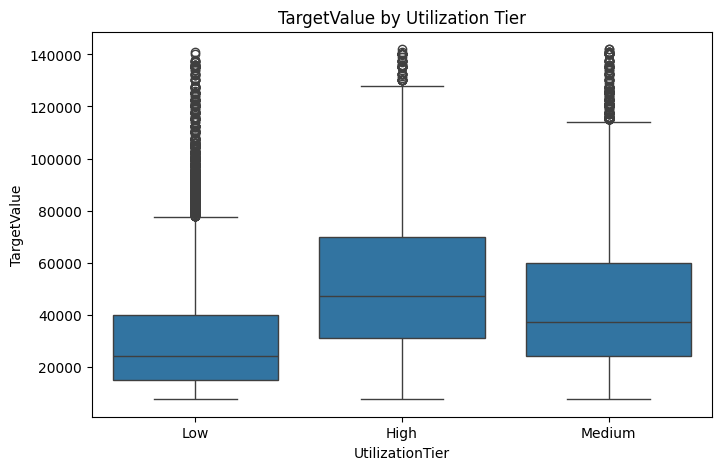

In [10]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=train,
    x='UtilizationTier',
    y='TargetValue'
)

plt.title('TargetValue by Utilization Tier')

plt.show()

> **Key Takeaways from the Boxplot:**
> * **Category Price Ranges:** It shows the median (average) selling price distribution across different usage levels (`Low`, `Medium`, `High`).
> * **Outlier Detection:** It highlights extreme price values (outliers) that deviate significantly from the typical selling price range in each tier.

### Top 10 Regions by Average Selling Price

Group by aggregation analysis to calculate and visualize the top 10 regions (`RegionCode`) with the highest average machinery selling prices (`TargetValue`).

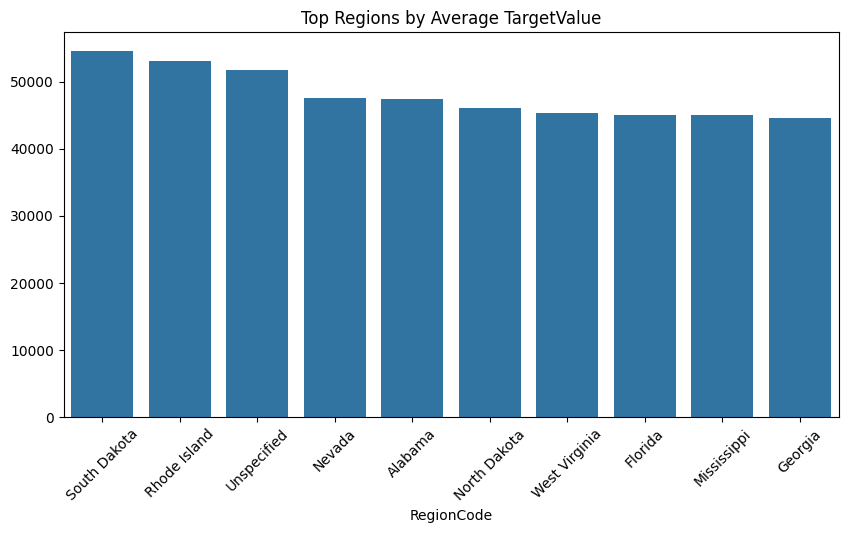

In [11]:
top_regions = (
    train.groupby('RegionCode')['TargetValue']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,5))

sns.barplot(
    x=top_regions.index,
    y=top_regions.values
)

plt.xticks(rotation=45)

plt.title('Top Regions by Average TargetValue')

plt.show()

> **EDA Insight & Key Takeaway:**
> * **Top 10 High-Value Regions:** By grouping the data by `RegionCode`, we identified the top 10 regions with the highest average machinery selling prices.
> * **Impact of Location on Price:** This indicates that an asset's geographic location significantly influences its overall valuation, making `RegionCode` an important predictive feature for our models.

### Manufacture Year Distribution Analysis

Visualizing the distribution of asset manufacturing years (`ManufactureYear`) to understand the age range of the machinery fleet and identify any potential data anomalies or unrealistic year values.

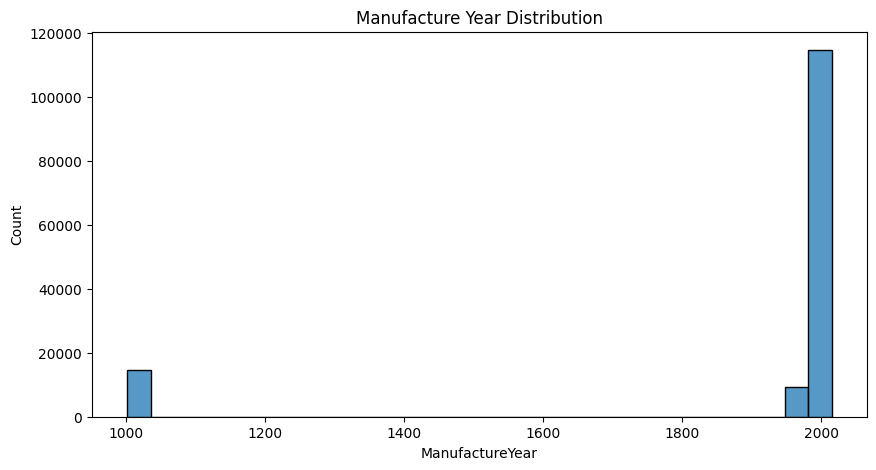

In [12]:
plt.figure(figsize=(10,5))

sns.histplot(
    train['ManufactureYear'],
    bins=30
)

plt.title('Manufacture Year Distribution')

plt.show()

> **EDA Insight & Key Takeaway:**
> * **Fleet Age Distribution:** Most machines in the dataset were manufactured in recent decades, showing the overall age breakdown of the inventory.
> * **Data Anomaly Identification:** The plot helps detect unrealistic outlier years (such as Year 1000 default values), highlighting the need for data cleaning before model training.

**Feature Enginerting**

In [13]:
print(train['AssetScaleFactor'].dtype)
print(train['AssetScaleFactor'].head(10))

object
0            Medium
1               NaN
2    Large / Medium
3               NaN
4              Mini
5             Large
6               NaN
7    Large / Medium
8               NaN
9               NaN
Name: AssetScaleFactor, dtype: object


### 4. Primary Feature Engineering: Date Extraction, Asset Age & Usage Metrics

Engineering domain-specific features across both train and test datasets:
* **Date Components:** Extracting year, month, quarter, day, and day of week from `TransactionDate` to capture temporal patterns.
* **Asset Age:** Calculating the operational age of the machine at the time of sale (`TransactionYear - ManufactureYear`).
* **Hours Per Year:** Normalizing operational hours by asset age (`OperationalHoursMeter / (AssetAge + 1)`) to measure yearly usage intensity while avoiding division by zero.
* **Specification Length:** Extracting string length from `Spec_FullDescriptor` as a numerical proxy for technical detail complexity.

In [14]:
for df in [train, test]:

    df['TransactionDate'] = pd.to_datetime(df['TransactionDate'])

    df['TransactionYear'] = df['TransactionDate'].dt.year
    df['TransactionMonth'] = df['TransactionDate'].dt.month
    df['TransactionQuarter'] = df['TransactionDate'].dt.quarter
    df['TransactionDay'] = df['TransactionDate'].dt.day
    df['DayOfWeek'] = df['TransactionDate'].dt.dayofweek

    df['AssetAge'] = (
        df['TransactionYear']
        - df['ManufactureYear']
    )

    df['HoursPerYear'] = (
        df['OperationalHoursMeter']
        /
        (df['AssetAge'] + 1)
    )

    df['SpecLength'] = (
        df['Spec_FullDescriptor']
        .astype(str)
        .str.len()
    )

### Frequency Encoding (Handling Text Columns with Many Unique Values)

Instead of using One-Hot Encoding (which creates too many columns), we replace each category with its occurrence count. 

This helps tree models easily learn which vendors and machine models are common versus rare. Missing categories in the test set are filled with `0`.

In [15]:
high_cardinality = [
    'AssetID',
    'VendorPartnerID',
    'ProductConfigID',
    'Spec_FullDescriptor',
    'Spec_BaseClass',
    'Spec_SubClass',
    'Spec_ReleaseSeries',
    'Spec_VariantModifier'
]

for col in high_cardinality:

    freq = train[col].value_counts()

    train[col + '_freq'] = train[col].map(freq)

    test[col + '_freq'] = test[col].map(freq)

    test[col + '_freq'] = test[col + '_freq'].fillna(0)

### Data Preparation & Train-Target Split

Dropping the original `TransactionDate` (features already extracted), separating input features (`X`) from the target (`y`) to prevent data leakage, and creating `y_log` using `np.log1p` to normalize the right-skewed target prices.

In [16]:
train = train.drop(columns=['TransactionDate'])
test = test.drop(columns=['TransactionDate'])
X = train.drop(columns=['TargetValue'])
y = train['TargetValue']
X_test = test.copy()

y_log = np.log1p(y)

**Preprocessing Pipeline**

In [17]:
numerical_features = X.select_dtypes(
    include=['int64','float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

numeric_transformer = Pipeline(
    steps=[
        ('imputer',
         SimpleImputer(strategy='median'))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer',
         SimpleImputer(strategy='most_frequent')),
        (
            'encoder',
            OrdinalEncoder(
                handle_unknown='use_encoded_value',
                unknown_value=-1
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            numeric_transformer,
            numerical_features
        ),
        (
            'cat',
            categorical_transformer,
            categorical_features
        )
    ]
)

### Train-Validation Split

Splitting the dataset into 80% training (`X_train`, `y_train`) and 20% validation (`X_valid`, `y_valid`) sets with a fixed `random_state=42` for reproducibility.

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y_log,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_valid.shape)

(110960, 64)
(27741, 64)


### RMSLE Function

Defining a custom Root Mean Squared Logarithmic Error (RMSLE) metric function:
* Converts log-transformed values back to their original selling price scale using `np.expm1`.
* Clips negative predictions to zero (`np.maximum(y_pred, 0)`) to prevent domain errors in logarithmic metrics.
* Calculates the RMSLE score between actual and predicted selling prices.

In [19]:
from sklearn.metrics import mean_squared_log_error

def rmsle_score(y_true_log, y_pred_log):

    y_true = np.expm1(y_true_log)
    y_pred = np.expm1(y_pred_log)

    y_pred = np.maximum(y_pred, 0)

    return np.sqrt(
        mean_squared_log_error(
            y_true,
            y_pred
        )
    )

### Model 1: Random Forest Regressor

We build and evaluate an ensemble **Random Forest Regressor** with 500 decision trees to establish a strong baseline score.

* **Architecture:** Random Forest uses **Bagging (Bootstrap Aggregating)**, training 500 decision trees in parallel on random sub-samples of data and averaging their predictions to reduce overall model variance.
* **Pipeline Execution:** Features are automatically cleaned and encoded via `preprocessor` before fitting the model to prevent data leakage.
* **Hyperparameters:**
  * `n_estimators=500`: Constructs 500 individual decision trees for stable, smoothed predictions.
  * `n_jobs=-1`: Utilizes all available CPU cores to execute parallel training efficiently.

In [20]:
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model',
     RandomForestRegressor(
    n_estimators=500,
    random_state=42,
    n_jobs=-1
     ))
])

rf_pipeline.fit(X_train, y_train)

rf_valid_pred = rf_pipeline.predict(X_valid)

rf_rmsle = rmsle_score(
    y_valid,
    rf_valid_pred
)

print("Random Forest RMSLE:", rf_rmsle)

Random Forest RMSLE: 0.22499539977007793


### Model 2: XGBoost Regressor (Gradient Boosting)

Building and evaluating an **XGBoost Regressor** pipeline with regularized hyperparameter settings to capture complex non-linear patterns and improve upon the Random Forest baseline.

* **Architecture:** XGBoost is a **Boosting** algorithm that builds decision trees sequentially, where each new tree focuses on correcting the residuals (errors) of the previous trees.
* **Hyperparameter Strategy:**
  * `n_estimators=600` & `learning_rate=0.05`: Slow, stable learning across 600 trees to prevent overfitting.
  * `max_depth=6` & `min_child_weight=5`: Controls tree depth and split requirements to balance complexity and generalizability.
  * `subsample=0.8` & `colsample_bytree=0.8`: Randomly selects 80% of rows and 80% of features per tree to prevent overfitting (stochastic gradient boosting).
  * `reg_alpha=0.1` & `reg_lambda=2`: L1 and L2 regularization penalties to constrain model weights and avoid overfitting noisy data.

In [21]:
from xgboost import XGBRegressor

xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model',
     XGBRegressor(
    n_estimators=600,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=2,
    random_state=42,
    n_jobs=-1
     ))
])

xgb_pipeline.fit(X_train, y_train)

xgb_valid_pred = xgb_pipeline.predict(X_valid)

xgb_rmsle = rmsle_score(
    y_valid,
    xgb_valid_pred
)

print("XGBoost RMSLE:", xgb_rmsle)

XGBoost RMSLE: 0.2344687289993194


### Model 3: LightGBM Regressor (Leaf-Wise Gradient Boosting)

Building and evaluating a **LightGBM Regressor** pipeline to leverage leaf-wise tree growth for fast training speed and high performance on structured data.

* **Architecture:** LightGBM grows trees **leaf-wise** rather than level-wise, allowing it to minimize loss faster and handle large datasets efficiently.
* **Hyperparameter Strategy:**
  * `n_estimators=1500` & `learning_rate=0.02`: A lower learning rate paired with more boosting rounds for smooth, gradual convergence.
  * `num_leaves=31`: Controls maximum tree complexity to prevent overfitting.
  * `subsample=0.8` & `colsample_bytree=0.8`: Feature and row sampling to add randomness and improve generalization.

In [22]:
from lightgbm import LGBMRegressor

lgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model',
     LGBMRegressor(
    n_estimators=1500,
    learning_rate=0.02,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
     ))
])

lgb_pipeline.fit(X_train, y_train)

lgb_valid_pred = lgb_pipeline.predict(X_valid)

lgb_rmsle = rmsle_score(
    y_valid,
    lgb_valid_pred
)

print("LightGBM RMSLE:", lgb_rmsle)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.023517 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3485
[LightGBM] [Info] Number of data points in the train set: 110960, number of used features: 57
[LightGBM] [Info] Start training from score 10.424734
LightGBM RMSLE: 0.2381575792047014


### Hyperparameter Tuning (LightGBM)

Using `RandomizedSearchCV` with 3-fold cross-validation to quickly tune LightGBM parameters (`n_estimators`, `learning_rate`, `num_leaves`) on the pipeline without data leakage.

In [23]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'model__n_estimators': [500, 800, 1000],
    'model__learning_rate': [0.03, 0.05, 0.1],
    'model__num_leaves': [31, 50, 100],
    'model__subsample': [0.8, 1.0],
    'model__colsample_bytree': [0.8, 1.0]
}

search = RandomizedSearchCV(
    lgb_pipeline,
    param_distributions=param_grid,
    n_iter=5,
    cv=3,
    scoring='neg_mean_squared_error',
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train)

best_lgb = search.best_estimator_

pred = best_lgb.predict(X_valid)

print("Best Parameters:", search.best_params_)
print("RMSLE:", rmsle_score(y_valid, pred))

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/v

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.020896 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3485
[LightGBM] [Info] Number of data points in the train set: 110960, number of used features: 57
[LightGBM] [Info] Start training from score 10.424734
Best Parameters: {'model__subsample': 1.0, 'model__num_leaves': 100, 'model__n_estimators': 800, 'model__learning_rate': 0.05, 'model__colsample_bytree': 1.0}
RMSLE: 0.22005232844054723


### Model Ensembling: Weighted Blending (XGBoost + LightGBM)

To leverage the complementary strengths of level-wise boosting (XGBoost) and leaf-wise boosting (LightGBM), we evaluate weighted average blends across three ratios on the validation predictions:
* **Blend 1:** 60% XGBoost + 40% LightGBM
* **Blend 2:** 70% XGBoost + 30% LightGBM
* **Blend 3:** 80% XGBoost + 20% LightGBM

Combining predictions from distinct tree-growth architectures reduces individual model variance and generalizes better on unseen data.

In [24]:
ensemble_60 = (
    0.6 * xgb_valid_pred +
    0.4 * lgb_valid_pred
)

ensemble_60_rmsle = rmsle_score(
    y_valid,
    ensemble_60
)

print("60-40 Ensemble RMSLE:", ensemble_60_rmsle)

60-40 Ensemble RMSLE: 0.23482897640431885


In [25]:
ensemble_70 = (
    0.7 * xgb_valid_pred +
    0.3 * lgb_valid_pred
)

ensemble_70_rmsle = rmsle_score(
    y_valid,
    ensemble_70
)

print("70-30 Ensemble RMSLE:", ensemble_70_rmsle)

70-30 Ensemble RMSLE: 0.23459825810124937


In [26]:
ensemble_80 = (
    0.8 * xgb_valid_pred +
    0.2 * lgb_valid_pred
)

ensemble_80_rmsle = rmsle_score(
    y_valid,
    ensemble_80
)

print("80-20 Ensemble RMSLE:", ensemble_80_rmsle)

80-20 Ensemble RMSLE: 0.2344612188041638


**Compare Models**

In [27]:
results = pd.DataFrame({
    'Model':[
        'Random Forest',
        'XGBoost',
        'LightGBM',
        'Ensemble 60-40',
        'Ensemble 70-30',
        'Ensemble 80-20'
    ],
    'RMSLE':[
        rf_rmsle,
        xgb_rmsle,
        lgb_rmsle,
        ensemble_60_rmsle,
        ensemble_70_rmsle,
        ensemble_80_rmsle
    ]
})

results.sort_values('RMSLE')

,Model,RMSLE
0,Random Forest,0.224995
5,Ensemble 80-20,0.234461
1,XGBoost,0.234469
4,Ensemble 70-30,0.234598
3,Ensemble 60-40,0.234829
2,LightGBM,0.238158


**Final Training on Full Data**

### -------------------------------EXTRAS(work in progress)---------------------------

**Feature Engineering Pipeline (with NLP)**

In [28]:
train_df = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')

test_df = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv')

In [29]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import OrdinalEncoder

def feature_engineering_with_nlp(train_df, test_df, text_cols, cat_cols):
    print(" Starting Feature Engineering & Text Processing...")
    
    # Combine data for consistent transformations
    train_df['is_train'] = 1
    test_df['is_train'] = 0
    df = pd.concat([train_df, test_df], ignore_index=True)
    
    # 1. Standard Cleaning (Handling Year 1000 Anomaly)
    if 'ManufactureYear' in df.columns:
        df['ManufactureYear'] = df['ManufactureYear'].replace(1000, np.nan)
        df['ManufactureYear'].fillna(df['ManufactureYear'].median(), inplace=True)
        
    # 2. Date Features (Assuming 'SaleDate' exists)
    if 'SaleDate' in df.columns:
        df['SaleDate'] = pd.to_datetime(df['SaleDate'])
        df['SaleYear'] = df['SaleDate'].dt.year
        df['SaleMonth'] = df['SaleDate'].dt.month
        df.drop('SaleDate', axis=1, inplace=True)
        
    # 3. Handle Operational Hours
    if 'OperationalHoursMeter' in df.columns:
        df['OperationalHoursMeter'] = np.where(df['OperationalHoursMeter'] > 1e5, np.nan, df['OperationalHoursMeter'])
        df['OperationalHoursMeter'].fillna(df['OperationalHoursMeter'].median(), inplace=True)
        
    # 4. NLP on Text Columns (TF-IDF + SVD)
    # Target specific messy string columns to extract latent features
    for col in text_cols:
        print(f" Processing NLP features for: {col}")
        df[col] = df[col].fillna('missing').astype(str).str.lower()
        
        # Initialize TF-IDF
        tfidf = TfidfVectorizer(max_features=500, token_pattern=r'(?u)\b\w+\b')
        tfidf_features = tfidf.fit_transform(df[col])
        
        # Reduce dimensionality with SVD (extracting top 10 concepts)
        svd = TruncatedSVD(n_components=10, random_state=42)
        svd_features = svd.fit_transform(tfidf_features)
        
        # Add SVD features back to dataframe
        for i in range(10):
            df[f'{col}_svd_{i}'] = svd_features[:, i]
            
        # We can drop the original text column now, or keep it for basic ordinal encoding too
        df.drop(col, axis=1, inplace=True)
        
    # 5. Ordinal Encoding for standard categorical features
    print(" Encoding Categorical Features...")
    for col in cat_cols:
        if col in df.columns:
            df[col] = df[col].fillna('Missing').astype(str)
            encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
            df[col] = encoder.fit_transform(df[[col]])
            
    # Split back to train and test
    train_processed = df[df['is_train'] == 1].drop(['is_train'], axis=1)
    test_processed = df[df['is_train'] == 0].drop(['is_train', 'TargetValue'], axis=1)
    
    print(" Feature Engineering Complete!")
    return train_processed, test_processed

# Define columns (You need to specify which ones are text vs categorical based on your dataset)
# Example: text_cols = ['MachineDescription', 'ProductConfigID']
text_columns_for_nlp = [] # ADD YOUR TEXT COLUMNS HERE
standard_categorical_cols = train_df.select_dtypes(include=['object']).columns.tolist()

# Ensure we don't double process
standard_categorical_cols = [c for c in standard_categorical_cols if c not in text_columns_for_nlp and c not in ['TargetValue', 'TransactionID']]

# Run pipeline
train_fe, test_fe = feature_engineering_with_nlp(train_df, test_df, text_cols=text_columns_for_nlp, cat_cols=standard_categorical_cols)

# Setup X and y
y_train = np.log1p(train_fe['TargetValue'])
X_train = train_fe.drop(['TargetValue', 'TransactionID'], axis=1)
X_test = test_fe.drop(['TransactionID'], axis=1)

 Starting Feature Engineering & Text Processing...
 Encoding Categorical Features...
 Feature Engineering Complete!


In [30]:
# ==========================================
#  SAFETY CHECK: ensure clean sequential index
# ==========================================
print("Before reset:")
print("X_train index is default range:", X_train.reset_index(drop=True).equals(X_train))
print("X_test index is default range:", X_test.reset_index(drop=True).equals(X_test))

X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)

print("\nAfter reset:")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("Index now 0 to n-1:", X_train.index[0], "to", X_train.index[-1])

Before reset:
X_train index is default range: True
X_test index is default range: False

After reset:
X_train shape: (138701, 48)
X_test shape: (15000, 48)
y_train shape: (138701,)
Index now 0 to n-1: 0 to 138700


In [31]:
from sklearn.model_selection import KFold
import numpy as np
import pandas as pd

# ==========================================
#  OUT-OF-FOLD TARGET ENCODING
# ==========================================
print(" Adding target encoding for high-cardinality categoricals...")

# Pick the columns most likely to benefit (high-cardinality identifiers)
target_encode_cols = [col for col in ['ProductConfigID', 'AssetID', 'Spec_FullDescriptor', 
                                        'Spec_BaseClass', 'Spec_SubClass'] 
                       if col in X_train.columns]

print("Target encoding columns:", target_encode_cols)

kf_te = KFold(n_splits=5, shuffle=True, random_state=42)

global_mean = y_train.mean()  # fallback for unseen categories

for col in target_encode_cols:
    # Initialize the new encoded column
    X_train[col + '_target_enc'] = 0.0
    
    # Out-of-fold encoding for train set (prevents leakage)
    for train_idx, valid_idx in kf_te.split(X_train):
        fold_train = X_train.iloc[train_idx]
        fold_target = y_train.iloc[train_idx]
        
        # Compute mean target per category using ONLY this fold's training portion
        means = fold_target.groupby(fold_train[col]).mean()
        
        # Apply to the held-out fold, fall back to global mean for unseen categories
        X_train.loc[X_train.index[valid_idx], col + '_target_enc'] = (
            X_train.iloc[valid_idx][col].map(means).fillna(global_mean).values
        )
    
    # For test set, use the FULL training data to compute means (no leakage risk here, 
    # since test set was never used to compute these means)
    full_means = y_train.groupby(X_train[col]).mean()
    X_test[col + '_target_enc'] = X_test[col].map(full_means).fillna(global_mean)

print(" Target encoding complete!")
print("New columns added:", [c + '_target_enc' for c in target_encode_cols])

 Adding target encoding for high-cardinality categoricals...
Target encoding columns: ['ProductConfigID', 'AssetID', 'Spec_FullDescriptor', 'Spec_BaseClass', 'Spec_SubClass']
 Target encoding complete!
New columns added: ['ProductConfigID_target_enc', 'AssetID_target_enc', 'Spec_FullDescriptor_target_enc', 'Spec_BaseClass_target_enc', 'Spec_SubClass_target_enc']


In [32]:
import lightgbm as lgb
import xgboost as xgb
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from scipy.optimize import minimize_scalar
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# ==========================================
#  MACHINE AGE FEATURE
# ==========================================
if 'SaleYear' in X_train.columns and 'ManufactureYear' in X_train.columns:
    X_train['MachineAge'] = X_train['SaleYear'] - X_train['ManufactureYear']
    X_test['MachineAge'] = X_test['SaleYear'] - X_test['ManufactureYear']
    X_train['MachineAge'] = X_train['MachineAge'].apply(lambda x: max(x, 0))
    X_test['MachineAge'] = X_test['MachineAge'].apply(lambda x: max(x, 0))

# ==========================================
#  CHECK: did earlier engineered features carry over?
# ==========================================
carried_over = [c for c in ['HoursPerYear', 'AssetAge', 'SpecLength'] if c in X_train.columns]
missing_features = [c for c in ['HoursPerYear', 'AssetAge', 'SpecLength'] if c not in X_train.columns]
print("Features already present:", carried_over)
print("Features missing (not carried into this pipeline):", missing_features)

cat_features = [col for col in X_train.columns if col in standard_categorical_cols]

# ==========================================
#  5-FOLD CV SETUP
# ==========================================
kf = KFold(n_splits=5, shuffle=True, random_state=42)

lgb_oof = np.zeros(len(X_train))
lgb_test_preds = np.zeros(len(X_test))

xgb_oof = np.zeros(len(X_train))
xgb_test_preds = np.zeros(len(X_test))

print(" Starting Training...")
print("-" * 50)

for fold, (train_idx, valid_idx) in enumerate(kf.split(X_train)):
    print(f"--- FOLD {fold + 1} ---")
    
    X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train.iloc[valid_idx], y_train.iloc[valid_idx]
    
    # ==========================================
    #  LIGHTGBM (tuned: more regularization, slower LR)
    # ==========================================
    lgb_params = {
        'objective': 'regression',
        'metric': 'rmse',
        'learning_rate': 0.01,
        'num_leaves': 63,
        'min_child_samples': 30,
        'feature_fraction': 0.8,
        'bagging_fraction': 0.8,
        'bagging_freq': 1,
        'lambda_l1': 0.1,
        'lambda_l2': 1.0,
        'random_state': 42,
        'verbose': -1
    }
    
    train_data = lgb.Dataset(X_tr, label=y_tr, categorical_feature=cat_features)
    valid_data = lgb.Dataset(X_va, label=y_va, categorical_feature=cat_features, reference=train_data)
    
    model_lgb = lgb.train(
        lgb_params,
        train_data,
        num_boost_round=10000,
        valid_sets=[train_data, valid_data],
        callbacks=[lgb.early_stopping(stopping_rounds=300, verbose=False)]
    )
    
    lgb_oof[valid_idx] = model_lgb.predict(X_va, num_iteration=model_lgb.best_iteration)
    lgb_test_preds += model_lgb.predict(X_test, num_iteration=model_lgb.best_iteration) / kf.n_splits
    
    lgb_rmse = np.sqrt(mean_squared_error(y_va, lgb_oof[valid_idx]))
    print(f" LGBM RMSE: {lgb_rmse:.4f}")

    # ==========================================
    #  XGBOOST (unchanged - already performing well)
    # ==========================================
    xgb_params = {
        'objective': 'reg:squarederror',
        'n_estimators': 8000,
        'learning_rate': 0.015,
        'max_depth': 9,
        'subsample': 0.7,
        'colsample_bytree': 0.7,
        'n_jobs': -1,
        'random_state': 42
    }
    
    model_xgb = xgb.XGBRegressor(**xgb_params, early_stopping_rounds=200)
    
    model_xgb.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        verbose=False
    )
    
    xgb_oof[valid_idx] = model_xgb.predict(X_va)
    xgb_test_preds += model_xgb.predict(X_test) / kf.n_splits
    
    xgb_rmse = np.sqrt(mean_squared_error(y_va, xgb_oof[valid_idx]))
    print(f" XGBoost RMSE: {xgb_rmse:.4f}\n")

# ==========================================
#  OVERALL EVALUATION + OPTIMAL BLEND WEIGHT
# ==========================================
cv_lgb_rmse = np.sqrt(mean_squared_error(y_train, lgb_oof))
cv_xgb_rmse = np.sqrt(mean_squared_error(y_train, xgb_oof))

print(f" LightGBM CV RMSE: {cv_lgb_rmse:.4f}  (previous run: 0.2195)")
print(f" XGBoost CV RMSE:  {cv_xgb_rmse:.4f}  (previous run: 0.2005)")

def blend_rmse(w):
    blend = w * xgb_oof + (1 - w) * lgb_oof
    return np.sqrt(mean_squared_error(y_train, blend))

res = minimize_scalar(blend_rmse, bounds=(0, 1), method='bounded')
best_w = res.x
print(f"Best XGB weight: {best_w:.3f}")
print(f"Optimized blend CV RMSE: {res.fun:.4f}  (previous run: 0.1972)")

# ==========================================
#  FINAL SUBMISSION (proven formula from the 0.192 run)
# ==========================================
final_ensemble_preds = (best_w * np.expm1(xgb_test_preds)) + ((1 - best_w) * np.expm1(lgb_test_preds))

submission = pd.DataFrame({
    'TransactionID': test_df['TransactionID'],
    'TargetValue': final_ensemble_preds
})

submission.to_csv('submission.csv', index=False)
print("Saved final submission to 'submission.csv'")

Features already present: []
Features missing (not carried into this pipeline): ['HoursPerYear', 'AssetAge', 'SpecLength']
 Starting Training...
--------------------------------------------------
--- FOLD 1 ---
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.177365 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3450
[LightGBM] [Info] Number of data points in the train set: 73973, number of used features: 57
[LightGBM] [Info] Start training from score 10.423536
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.074083 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3450
[LightGBM] [Info] Number of data points in the train set: 73973, number of used features: 57
[LightGBM] [Info] Start train